In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DATA_PATH = Path("../data/raw/BTCUSDT_5m.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["open_time"])
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

Dataset loaded: 51,839 rows, 10 columns


In [16]:
display(df.head())

,open_time,open,high,low,close,volume,quote_volume,number_of_trades,taker_buy_base_volume,taker_buy_quote_volume
0,2026-05-04 10:30:00+00:00,78508.32,78964.22,78452.45,78956.55,456.79764,3.599900e+07,43102,329.74288,2.598751e+07
1,2026-05-04 10:35:00+00:00,78956.56,79033.09,78899.35,78936.15,343.51524,2.711996e+07,23163,142.08025,1.121735e+07
2,2026-05-04 10:40:00+00:00,78936.15,79021.42,78916.90,78916.91,235.42347,1.858924e+07,19993,71.34801,5.633704e+06
3,2026-05-04 10:45:00+00:00,78916.91,79070.47,78890.03,79070.46,135.93761,1.073257e+07,17469,56.40571,4.453903e+06
4,2026-05-04 10:50:00+00:00,79070.47,79099.98,78931.18,78931.18,96.72727,7.645495e+06,9723,57.82202,4.571129e+06


In [17]:
display(df.sample(5,random_state=67))

,open_time,open,high,low,close,volume,quote_volume,number_of_trades,taker_buy_base_volume,taker_buy_quote_volume
49590,2026-10-23 15:00:00+00:00,81784.00,81814.01,81560.00,81560.01,88.47388,7.227571e+06,15680,26.15361,2.136690e+06
51333,2026-10-29 16:15:00+00:00,81720.01,81720.01,81444.70,81444.71,92.53929,7.548204e+06,19697,28.35356,2.312834e+06
2573,2026-05-13 08:55:00+00:00,81172.70,81196.76,81172.70,81196.57,14.13809,1.147731e+06,2946,9.37617,7.611600e+05
14084,2026-06-22 08:10:00+00:00,64274.80,64313.60,64221.51,64313.60,31.78514,2.042449e+06,7375,17.20265,1.105540e+06
30721,2026-08-19 02:35:00+00:00,64373.92,64408.04,64373.92,64407.50,25.73443,1.657221e+06,4990,14.52961,9.356095e+05


In [20]:
print("Dataset shape:", df.shape)
print("Column names :", df.columns.tolist())
print("Data types   :",)
display(df.dtypes)

Dataset shape: (51839, 10)
Column names : ['open_time', 'open', 'high', 'low', 'close', 'volume', 'quote_volume', 'number_of_trades', 'taker_buy_base_volume', 'taker_buy_quote_volume']
Data types   :


open_time                 datetime64[ns, UTC]
open                                  float64
high                                  float64
low                                   float64
close                                 float64
volume                                float64
quote_volume                          float64
number_of_trades                        int64
taker_buy_base_volume                 float64
taker_buy_quote_volume                float64
dtype: object

In [21]:
print("Summary statistics:")
display(df.describe().T)

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
open,51839.0,7.275555e+04,8.588267e+03,58169.820000,6.400774e+04,7.649001e+04,8.062495e+04,8.727842e+04
high,51839.0,7.280362e+04,8.590560e+03,58298.000000,6.404153e+04,7.653801e+04,8.066807e+04,8.739567e+04
low,51839.0,7.270696e+04,8.585743e+03,57800.190000,6.397500e+04,7.642431e+04,8.057780e+04,8.715400e+04
close,51839.0,7.275553e+04,8.588255e+03,58169.810000,6.400775e+04,7.649000e+04,8.062495e+04,8.727842e+04
volume,51839.0,5.585830e+01,7.738124e+01,0.803120,2.003749e+01,3.480103e+01,6.307869e+01,2.974591e+03
quote_volume,51839.0,4.039886e+06,5.508164e+06,50654.179850,1.441578e+06,2.536572e+06,4.603507e+06,2.033418e+08
number_of_trades,51839.0,1.037140e+04,1.021363e+04,290.000000,4.329000e+03,7.435000e+03,1.257300e+04,2.152200e+05
taker_buy_base_volume,51839.0,2.769021e+01,4.010949e+01,0.170300,8.962470e+00,1.672979e+01,3.139997e+01,1.838424e+03
taker_buy_quote_volume,51839.0,2.003726e+06,2.869807e+06,10741.755041,6.441268e+05,1.213362e+06,2.302337e+06,1.255895e+08


In [19]:
print("Missing values:")
display(df.isna().sum())

Missing values:


open_time                 0
open                      0
high                      0
low                       0
close                     0
volume                    0
quote_volume              0
number_of_trades          0
taker_buy_base_volume     0
taker_buy_quote_volume    0
dtype: int64

In [30]:
print("Duplicate timestamps        : ", df["open_time"].duplicated().sum())
print("Duplicate rows              : ", df.duplicated().sum())
print("Chronologically sorted      : ", df["open_time"].is_monotonic_increasing)
print("Non-positive closing prices : ", (df["close"] <= 0).sum())
print("Negative volume             : ", (df["volume"] < 0).sum())

Duplicate timestamps        :  0
Duplicate rows              :  0
Chronologically sorted      :  True
Non-positive closing prices :  0
Negative volume             :  0


In [31]:
intervals = df["open_time"].diff()
print("\nCandle interval counts:")
display(intervals.value_counts().head())

print("Intervals longer than 5 minutes:",
      (intervals > pd.Timedelta(minutes=5)).sum())


Candle interval counts:


open_time
0 days 00:05:00    51838
Name: count, dtype: int64

Intervals longer than 5 minutes: 0


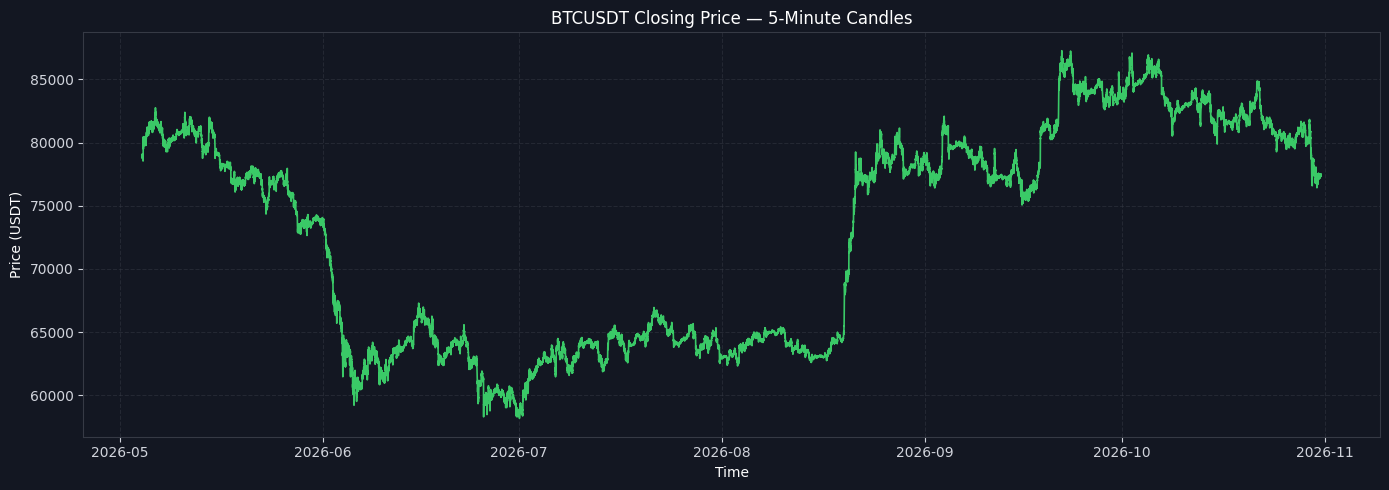

In [34]:
plt.figure(figsize=(14, 5), facecolor="#131722")

ax = plt.gca()
ax.set_facecolor("#131722")

plt.plot(df["open_time"], df["close"], color="#3AC967", linewidth=1.2)

plt.title("BTCUSDT Closing Price — 5-Minute Candles", color="white")
plt.xlabel("Time", color="white")
plt.ylabel("Price (USDT)", color="white")

ax.tick_params(colors="#D1D4DC")
ax.spines["bottom"].set_color("#363A45")
ax.spines["top"].set_color("#363A45")
ax.spines["left"].set_color("#363A45")
ax.spines["right"].set_color("#363A45")

plt.grid(True, color="#363A45", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

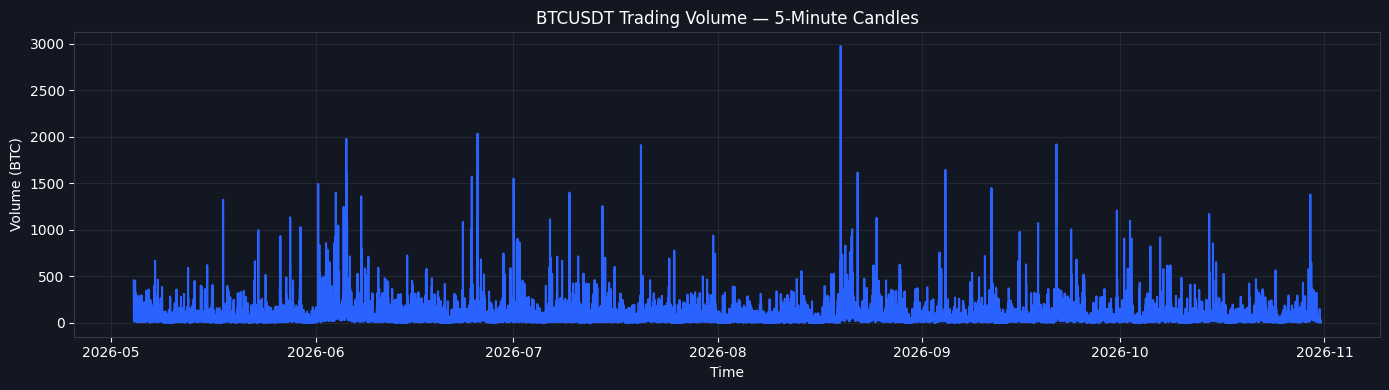

In [35]:
plt.figure(figsize=(14, 4), facecolor="#131722")
ax = plt.gca()
ax.set_facecolor("#131722")

plt.plot(df["open_time"], df["volume"], color="#2962FF")

plt.title("BTCUSDT Trading Volume — 5-Minute Candles", color="white")
plt.xlabel("Time", color="white")
plt.ylabel("Volume (BTC)", color="white")

ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("#363A45")

plt.grid(True, color="#363A45", alpha=0.5)
plt.tight_layout()
plt.show()

Return statistics:


count    5.183800e+04
mean     3.209206e-07
std      1.165584e-03
min     -1.841271e-02
25%     -4.945028e-04
50%     -1.176657e-07
75%      4.767931e-04
max      2.764312e-02
Name: return, dtype: float64

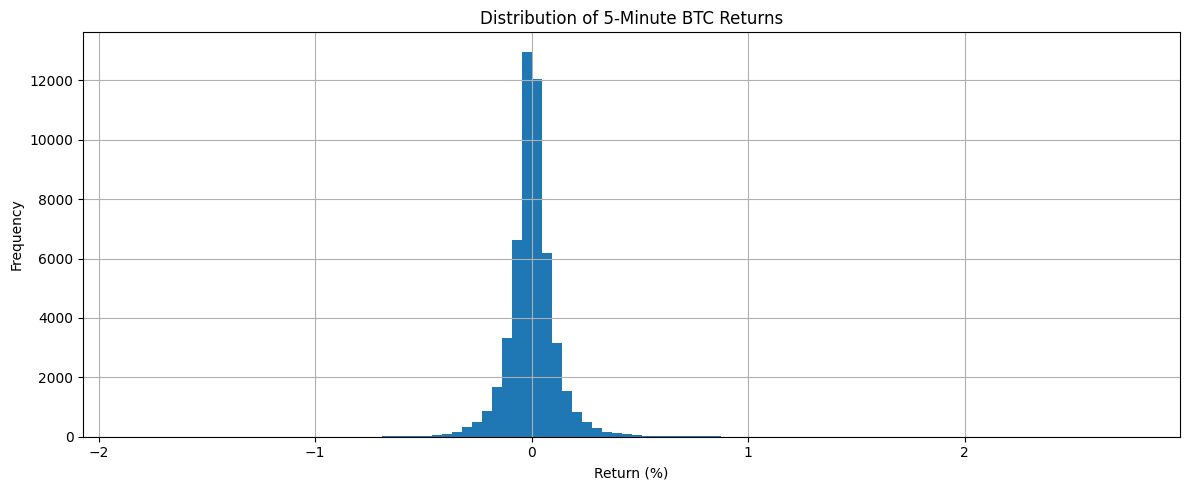

In [36]:
df["return"] = df["close"].pct_change()

print("Return statistics:")
display(df["return"].describe())

plt.figure(figsize=(12, 5))
plt.hist(df["return"].dropna() * 100, bins=100)
plt.title("Distribution of 5-Minute BTC Returns")
plt.xlabel("Return (%)")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
# Buying activity

df["taker_buy_ratio"] = (df["taker_buy_base_volume"] / df["volume"].replace(0, np.nan))
df["taker_buy_ratio"].describe()

count    51839.000000
mean         0.498615
std          0.171957
min          0.012327
25%          0.376261
50%          0.499103
75%          0.620075
max          0.985873
Name: taker_buy_ratio, dtype: float64

In [41]:
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("-" * 40)
print(f"Rows                        : {len(df):,}")
print(f"Columns in raw CSV          : {len(df.columns) - 2}")
print(f"Start                       : {df['open_time'].min()}")
print(f"End                         : {df['open_time'].max()}")
print(f"Missing values in raw CSV   : {df.drop(columns=['return', 'taker_buy_ratio']).isna().sum().sum()}")
print(f"Duplicate timestamps        : {df['open_time'].duplicated().sum()}")
print(f"Mean 5-minute return        : {df['return'].mean():.6%}")
print(f"Return standard deviation   : {df['return'].std():.6%}")

EXPLORATORY DATA ANALYSIS SUMMARY
----------------------------------------
Rows                        : 51,839
Columns in raw CSV          : 10
Start                       : 2026-05-04 10:30:00+00:00
End                         : 2026-10-31 10:20:00+00:00
Missing values in raw CSV   : 0
Duplicate timestamps        : 0
Mean 5-minute return        : 0.000032%
Return standard deviation   : 0.116558%
